In [1]:
import sys, warnings
sys.path.append('..')
warnings.filterwarnings('ignore')

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style='whitegrid')

from src.data.loader import load_raw_data, basic_clean
from src.features.engineering import add_behavioural_features

df = basic_clean(load_raw_data())
df = add_behavioural_features(df)
df.head()

2026-10-31 20:59:26,997 | INFO     | src.data.loader | load_raw_data:113 | Loading dataset from C:\All\why\data\raw\UCI_Credit_Card.csv


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,N_MONTHS_DELAY,MAX_DELAY_SEVERITY,N_MONTHS_PAID_DULY,MEAN_DELAY,DELAY_STD,DELAY_WEIGHTED,LONGEST_DELAY_STREAK,BILL_TREND,PAY_TREND,DELAY_TREND
0,1,20000,2,2,1,24,2,2,-1,-1,...,2,2,4,-0.333333,1.699673,0.428571,2,3913,0,4
1,2,120000,2,2,2,26,-1,2,0,0,...,2,2,4,0.500000,1.118034,0.285714,1,-579,-2000,-3
2,3,90000,2,2,2,34,0,0,0,0,...,0,0,6,0.000000,0.000000,0.000000,0,13690,-3482,0
3,4,50000,2,2,1,37,0,0,0,0,...,0,0,6,0.000000,0.000000,0.000000,0,17443,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,0,0,6,-0.333333,0.471405,-0.476190,0,-10514,1321,-1


## Engineered features summary

In [2]:
new_cols = ['BILL_TOTAL', 'BILL_STD', 'BILL_MAX', 'PAY_TOTAL', 'PAY_STD', 'PAY_MAX',
            'PAY_TO_BILL_RATIO', 'UTILIZATION',
            'UTILIZATION_MEAN', 'UTILIZATION_MAX', 'UTILIZATION_STD',
            'COVERAGE_MEAN', 'COVERAGE_MIN', 'LOG_LIMIT_BAL',
            'LOG_BILL_AMT1', 'LOG_PAY_AMT1',
            'N_MONTHS_DELAY', 'MAX_DELAY_SEVERITY', 'MEAN_DELAY', 'DELAY_STD',
            'DELAY_WEIGHTED', 'LONGEST_DELAY_STREAK', 'N_MONTHS_PAID_DULY',
            'BILL_TREND', 'PAY_TREND', 'DELAY_TREND']
df[new_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
BILL_TOTAL,30000.0,269861.671200,379564.331162,-336259.000000,28688.000000,126311.000000,342626.500000,5.263883e+06
BILL_STD,30000.0,11025.461142,18533.241758,0.000000,1414.890798,4180.640449,13101.760538,5.913469e+05
BILL_MAX,30000.0,60572.436867,78404.814025,-6029.000000,10060.000000,31208.500000,79599.000000,1.664089e+06
PAY_TOTAL,30000.0,31651.392567,60827.677939,0.000000,6679.750000,14383.000000,33503.500000,3.764066e+06
PAY_STD,30000.0,5299.141363,13698.941889,0.000000,561.738478,1290.520270,3767.379649,5.934559e+05
PAY_MAX,30000.0,15848.230133,37933.561204,0.000000,2198.000000,5000.000000,12100.000000,1.684259e+06
PAY_TO_BILL_RATIO,30000.0,21.216778,1255.766173,0.000000,0.041302,0.087865,0.608768,1.620000e+05
UTILIZATION,30000.0,0.373041,0.351882,-0.232585,0.029997,0.284829,0.687927,5.364040e+00
UTILIZATION_MEAN,30000.0,0.373041,0.351882,-0.232585,0.029997,0.284829,0.687927,5.364040e+00
UTILIZATION_MAX,30000.0,0.494955,0.433036,-0.099990,0.070636,0.430694,0.923225,1.068844e+01


## Behavioural split by target class
#
`N_MONTHS_DELAY`, `MAX_DELAY_SEVERITY`, `DELIEVER`... `DELAY_WEIGHTED` and
`UTILIZATION` separate defaulters from payers nicely — they aggregate raw
payment history into monotonic business signals.

                      Payers (0)  Defaulters (1)
BILL_TOTAL            272428.908      260822.956
BILL_STD               11814.061        8248.962
BILL_MAX               62281.977       54553.495
PAY_TOTAL              34969.421       19969.294
PAY_STD                 5839.579        3396.370
PAY_MAX                17502.722       10023.101
PAY_TO_BILL_RATIO         25.817           5.019
UTILIZATION                0.351           0.449
UTILIZATION_MEAN           0.351           0.449
UTILIZATION_MAX            0.476           0.561
UTILIZATION_STD            0.091           0.086
COVERAGE_MEAN            206.535         107.204
COVERAGE_MIN               0.052           0.027
LOG_LIMIT_BAL             11.750          11.357
LOG_BILL_AMT1              8.985           8.817
LOG_PAY_AMT1               6.925           5.591
N_MONTHS_DELAY             0.504           1.996
MAX_DELAY_SEVERITY         0.201           1.274
MEAN_DELAY                -0.330           0.337
DELAY_STD           

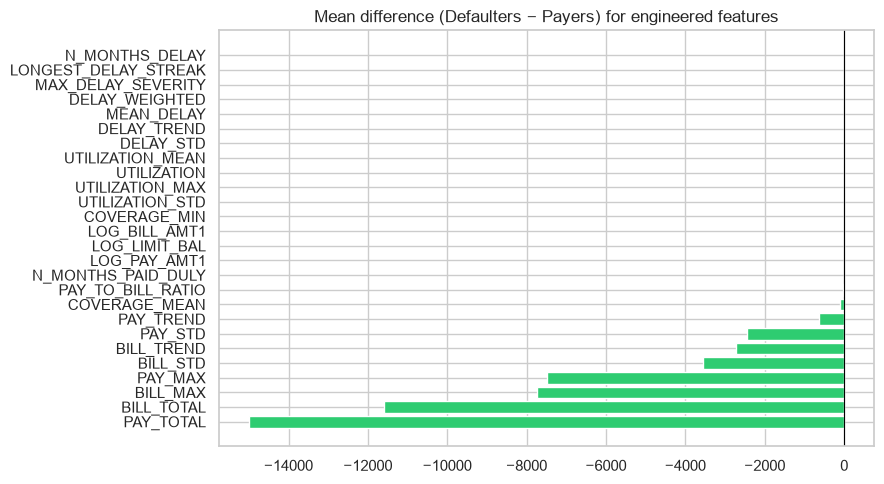

In [3]:
group = df.groupby('default_payment_next_month')[new_cols].mean().T
group.columns = ['Payers (0)', 'Defaulters (1)']
print(group.round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 5))
diff = (group['Defaulters (1)'] - group['Payers (0)']).sort_values()
colors = ['#e74c3c' if v > 0 else '#2ecc71' for v in diff]
ax.barh(list(diff.index), diff.values, color=colors)
ax.axvline(0, color='black', lw=0.8)
ax.set_title('Mean difference (Defaulters − Payers) for engineered features')
plt.tight_layout()
plt.savefig('../reports/figures/02_feature_split.png', dpi=110)
plt.show()